In [1]:
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt
import torch.nn.functional as F

In [2]:
TEXT_COL = "sentence"
LABEL_COL = "label"

SAMPLE_SIZE = 200
RANDOM_SEED = 20261025
NUM_REPETITIONS = 10

from pathlib import Path
from datetime import datetime
import json
import pickle

OUTPUT_DIR = Path("results") / ("uncertainty10_gpu_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
print("Results directory:", OUTPUT_DIR.resolve())
if not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable: select the RTX 5080 Python environment before running.")
print("GPU:", torch.cuda.get_device_name(0))
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased",
]
# Avoid TF32 approximation when comparing CPU/GPU cosine scores.
torch.backends.cuda.matmul.allow_tf32 = False


Results directory: /home/amyliu/Desktop/GR/Financial/results/uncertainty10_gpu_20261025_153340
GPU: NVIDIA GeForce RTX 5080


In [3]:
csv = "financial_original.csv"
df = pd.read_csv(csv)
print(df.head())
print(df.columns)
print(df.shape)

                                            sentence  label
0  According to Gran , the company has no plans t...      1
1  Technopolis plans to develop in stages an area...      1
2  The international electronic industry company ...      0
3  With the new production plant the company woul...      2
4  According to the company 's updated strategy f...      2
Index(['sentence', 'label'], dtype='str')
(4846, 2)


In [4]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"[?|!|\'|\"|#]", "", text)
    text = re.sub(r"[.|,|)|(|\\|/]", " ", text)
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def load_and_clean_dataset(csv_file):
    df = pd.read_csv(csv_file)
    df = df[[TEXT_COL, LABEL_COL]].dropna().drop_duplicates().copy()

    df["clean_sentence"] = df[TEXT_COL].apply(clean_text)
    df["length"] = df["clean_sentence"].apply(len)

    print(df.head())
    print(df[LABEL_COL].value_counts())
    print(df.shape)

    return df

In [5]:
def add_length_quantile_groups(df, num_quantiles=100):
    df = df.copy()

    quantiles = df["length"].quantile(
        [i / num_quantiles for i in range(1, num_quantiles)]
    ).tolist()

    quantiles = np.unique(quantiles).tolist()

    bins = [df["length"].min()] + quantiles + [df["length"].max()]
    labels = [f"Q{i+1}" for i in range(len(bins) - 1)]

    df["quantiles"] = pd.cut(
        df["length"],
        bins=bins,
        labels=labels,
        include_lowest=True,
        duplicates="drop"
    )

    print(df["quantiles"].value_counts().sort_index())

    return df

In [6]:
def add_length_quantile_groups(df, num_quantiles=100):
    df = df.copy()

    quantiles = df["length"].quantile(
        [i / num_quantiles for i in range(1, num_quantiles)]
    ).tolist()

    quantiles = np.unique(quantiles).tolist()

    bins = [df["length"].min()] + quantiles + [df["length"].max()]
    labels = [f"Q{i+1}" for i in range(len(bins) - 1)]

    df["quantiles"] = pd.cut(
        df["length"],
        bins=bins,
        labels=labels,
        include_lowest=True,
        duplicates="drop"
    )

    print(df["quantiles"].value_counts().sort_index())

    return df

In [7]:
df = load_and_clean_dataset(csv)
df = add_length_quantile_groups(df)
print(df.head())
print(df.columns)
print(df.shape)

                                            sentence  label  \
0  According to Gran , the company has no plans t...      1   
1  Technopolis plans to develop in stages an area...      1   
2  The international electronic industry company ...      0   
3  With the new production plant the company woul...      2   
4  According to the company 's updated strategy f...      2   

                                      clean_sentence  length  
0  According to Gran the company has no plans to ...     121  
1  Technopolis plans to develop in stages an area...     186  
2  The international electronic industry company ...     224  
3  With the new production plant the company woul...     204  
4  According to the company s updated strategy fo...     198  
label
1    2873
2    1363
0     604
Name: count, dtype: int64
(4840, 4)
quantiles
Q1      51
Q2      46
Q3      55
Q4      43
Q5      47
        ..
Q96     41
Q97     49
Q98     50
Q99     48
Q100    46
Name: count, Length: 100, dtype: int64
 

In [8]:
def sample_from_length_groups(df, sample_size=200, num_quantiles=100, random_seed=42):
    n_samples = sample_size // num_quantiles

    sampled_df = (
        df.groupby("quantiles", group_keys=False)
        .apply(lambda x: x.sample(n=min(n_samples, len(x)), random_state=random_seed))
        .reset_index(drop=True)
    )

    print("Actual Sample Size:", len(sampled_df))
    print("Minimum Token Count:", sampled_df["clean_sentence"].str.split().apply(len).min())
    print("Average Token Count:", sampled_df["clean_sentence"].str.split().apply(len).mean())
    print("Maximum Token Count:", sampled_df["clean_sentence"].str.split().apply(len).max())

    return sampled_df

In [9]:
sampled_df = sample_from_length_groups(
    df=df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    random_seed=RANDOM_SEED
)

Actual Sample Size: 200
Minimum Token Count: 3
Average Token Count: 21.605
Maximum Token Count: 72


In [10]:
sampled_df.head()

,sentence,label,clean_sentence,length
0,Registration is required .,1,Registration is required,24
1,The sales price was not disclosed .,1,The sales price was not disclosed,33
2,An Android app will be coming soon .,1,An Android app will be coming soon,34
3,Together they generate Aspo 's goodwill .,1,Together they generate Aspo s goodwill,38
4,Nokia has enough users to do just as well .,1,Nokia has enough users to do just as well,41


In [11]:
df["labels"] = (
    df["label"]
    .apply(
        lambda value: [
            str(int(value))
        ]
    )
)

print(
    df[
        [
            "label",
            "labels",
        ]
    ].head()
)

   label labels
0      1    [1]
1      1    [1]
2      0    [0]
3      2    [2]
4      2    [2]


In [12]:
from transformers import (
    AutoTokenizer,
    AutoModel,
)


def compute_embeddings(
    texts,
    model_name,
    batch_size=64,
    max_token=128,
):
    # Auto classes support all seven model checkpoints
    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=True,
    )

    model = AutoModel.from_pretrained(
        model_name,
    )

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    model = model.to(device)
    model.eval()

    all_embeddings = []

    for start_index in range(
        0,
        len(texts),
        batch_size,
    ):
        batch_texts = texts[
            start_index:
            start_index + batch_size
        ]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token,
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            outputs = model(**inputs)

            token_embeddings = (
                outputs.last_hidden_state
            )

            # Shape:
            # attention_mask:
            # [batch_size, sequence_length]
            #
            # expanded_mask:
            # [batch_size, sequence_length, 1]
            expanded_mask = (
                inputs["attention_mask"]
                .unsqueeze(-1)
                .to(token_embeddings.dtype)
            )

            # Sum only real-token embeddings
            summed_embeddings = (
                token_embeddings
                * expanded_mask
            ).sum(dim=1)

            # Number of real tokens in each text
            valid_token_counts = (
                expanded_mask
                .sum(dim=1)
                .clamp(min=1e-9)
            )

            # Masked mean pooling
            batch_embeddings = (
                summed_embeddings
                / valid_token_counts
            )

        all_embeddings.append(
            batch_embeddings.cpu()
        )

    embeddings = torch.cat(
        all_embeddings,
        dim=0,
    )

    print(
        "Model:",
        model_name,
    )
    print(
        "Device:",
        device,
    )
    print(
        "Embedding shape:",
        tuple(embeddings.shape),
    )

    return embeddings

In [13]:
def asymmetry_eta(x, bandwidth=None):
    """Original leave-one-out eta estimator, evaluated in float64 on CUDA.

    Row chunks limit GPU memory; strict empirical CDF handles ties exactly.
    """
    with torch.inference_mode():
        x = torch.as_tensor(np.asarray(x, dtype=float), device="cuda", dtype=torch.float64)
        x = x[~torch.isnan(x)]
        n = x.numel()
        if n < 3:
            return np.nan
        s = x.std(correction=1)
        q = torch.quantile(x, torch.tensor([0.25, 0.75], device=x.device, dtype=x.dtype))
        iqr = q[1] - q[0]
        sigma = torch.minimum(s, iqr / 1.349) if iqr.item() > 0 else s
        if torch.isclose(sigma, torch.zeros_like(sigma), rtol=1e-5, atol=1e-8).item():
            sigma = s if s.item() > 0 else x.new_tensor(1.0)
        h = x.new_tensor(bandwidth) if bandwidth is not None else 0.9 * sigma * n ** (-1 / 5)
        if h.item() <= 0:
            h = 1.06 * (s if s.item() > 0 else x.new_tensor(1.0)) * n ** (-1 / 5)
        f_hat = torch.empty_like(x)
        normalizer = (2 * np.pi) ** -0.5
        for start in range(0, n, 128):
            end = min(start + 128, n)
            kernel = (x.unsqueeze(0) - x[start:end].unsqueeze(1)) / h
            kernel.square_().mul_(-0.5).exp_().mul_(normalizer)
            kernel[torch.arange(end-start, device=x.device), torch.arange(start,end,device=x.device)] = 0
            f_hat[start:end] = kernel.sum(dim=1) / ((n - 1) * h)
        F_hat = torch.searchsorted(torch.sort(x).values, x, right=False).to(x.dtype) / (n - 1)
        if f_hat.std(correction=1).item() == 0 or F_hat.std(correction=1).item() == 0:
            return np.nan
        return (-torch.corrcoef(torch.stack((f_hat, F_hat)))[0, 1]).item()


In [14]:
def chi2_distance(dist1, dist2, bins=50, value_range=None, eps=1e-12):
    # Preserve NumPy bin edges and boundary conventions; count and reduce on GPU.
    edges = np.histogram_bin_edges(dist1, bins=bins, range=value_range)
    edges = torch.as_tensor(edges, device="cuda", dtype=torch.float64)
    def histogram(values):
        values = torch.as_tensor(np.asarray(values), device="cuda", dtype=torch.float64)
        valid = (values >= edges[0]) & (values <= edges[-1])
        indices = torch.bucketize(values[valid], edges, right=True) - 1
        indices.clamp_(max=edges.numel()-2)
        counts = torch.bincount(indices, minlength=edges.numel()-1).to(torch.float64)
        return counts / counts.sum()
    p, q = histogram(dist1), histogram(dist2)
    return (0.5 * ((p-q).square() / (p+q+eps)).sum()).item()


In [15]:
def create_cosine_similarity_matrix(embeddings):
    with torch.inference_mode():
        normalized = F.normalize(embeddings.detach().to("cuda", dtype=torch.float32), p=2, dim=1)
        return (normalized @ normalized.T).cpu().numpy()


In [16]:
from collections import defaultdict
from itertools import combinations

import numpy as np


def convert_to_label_sets(labels):
    label_sets = []

    for document_labels in labels:
        if isinstance(
            document_labels,
            str,
        ):
            label_set = {
                document_labels
            }
        else:
            label_set = set(
                document_labels
            )

        label_sets.append(
            label_set
        )

    return label_sets

In [17]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        shared_labels = (
            label_sets[first_index]
            .intersection(
                label_sets[second_index]
            )
        )

        # Same-label means at least one
        # shared label.
        if not shared_labels:
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add once to the overall distribution,
        # regardless of how many labels are shared.
        all_scores.append(
            score
        )

        # Per-label diagnostic data.
        # The score can appear in multiple label
        # groups here, but not in all_scores.
        for label in shared_labels:
            scores_by_label[
                label
            ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No within-label document "
            "pairs were found."
        )

    scores_by_label = {
        label: np.asarray(
            label_scores,
            dtype=float,
        )
        for label, label_scores
        in sorted(
            scores_by_label.items()
        )
    }

    print(
        "Total unique within-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label:
        return (
            all_scores,
            scores_by_label,
        )

    return all_scores

In [18]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label_pair = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        first_label_set = (
            label_sets[first_index]
        )

        second_label_set = (
            label_sets[second_index]
        )

        # Different-label means no shared labels.
        if not first_label_set.isdisjoint(
            second_label_set
        ):
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add each document pair exactly once.
        all_scores.append(
            score
        )

        # Store the full label-set pair only
        # for diagnostic purposes.
        first_key = tuple(
            sorted(first_label_set)
        )

        second_key = tuple(
            sorted(second_label_set)
        )

        label_set_pair = tuple(
            sorted(
                (
                    first_key,
                    second_key,
                )
            )
        )

        scores_by_label_pair[
            label_set_pair
        ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No between-label document "
            "pairs were found."
        )

    scores_by_label_pair = {
        label_pair: np.asarray(
            pair_scores,
            dtype=float,
        )
        for label_pair, pair_scores
        in scores_by_label_pair.items()
    }

    print(
        "Number of label-set pair types:",
        len(scores_by_label_pair),
    )

    print(
        "Total unique between-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label_pair:
        return (
            all_scores,
            scores_by_label_pair,
        )

    return all_scores

In [19]:
def bootstrap_chi2_from_existing_scores(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):

    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)

    # same-label statistics, fixed across bootstrap
    same_mean = torch.as_tensor(same_scores, device="cuda", dtype=torch.float64).mean().item()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    n_pair_types = len(label_pairs)

    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []

    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []

        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])

            n_sample = base_n + (1 if k < remainder else 0)

            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )

            sampled_diff_scores.extend(sampled_cosine_scores)

        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = torch.as_tensor(sampled_diff_scores, device="cuda", dtype=torch.float64).mean().item()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        eta_gap = same_eta - diff_eta
        abs_eta_gap = abs(eta_gap)

        chi2_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            "eta_gap": eta_gap,
            "abs_eta_gap": abs_eta_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(chi2_result)
        if (b + 1) % 100 == 0:
            print(f"Bootstrap {b + 1}/{n_bootstrap}", flush=True)

    bootstrap_chi2_df = pd.DataFrame(bootstrap_rows)

    chi2_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_chi2_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_chi2_df["diff_mean"].std(),

        "diff_eta": bootstrap_chi2_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_chi2_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_chi2_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_chi2_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_chi2_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_chi2_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_chi2_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_chi2_df["eta_gap"].std(),
        "abs_eta_gap": bootstrap_chi2_df["abs_eta_gap"].mean(),

        # averaged chi-square distance
        "chi2_distance": bootstrap_chi2_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_chi2_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_chi2_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_chi2_df, chi2_summary

In [20]:
def run_one_model_chi2_bootstrap(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    text_col="training_text",
    label_col="labels",
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(
        f"\nRunning model: {model_name}"
    )

    # Ohsumed text and multi-label columns
    texts = (
        sampled_df[text_col]
        .astype(str)
        .tolist()
    )

    # Keep labels as list of lists:
    # [["C01"], ["C02", "C03"], ...]
    labels = (
        sampled_df[label_col]
        .tolist()
    )

    # 1. Compute pretrained embeddings once
    embeddings = compute_embeddings(
        texts=texts,
        model_name=model_name,
        batch_size=batch_size,
        max_token=max_token,
    )

    # 2. Same-label cosine distribution
    same_scores, scores_by_label = (
        calculate_within_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label=True,
        )
    )

    # 3. Different-label cosine distribution
    diff_scores_original, diff_label = (
        calculate_between_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label_pair=True,
        )
    )

    # 4. Bootstrap the already-computed
    # different-label cosine scores
    (
        bootstrap_chi2_df,
        chi2_summary,
    ) = bootstrap_chi2_from_existing_scores(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth,
    )

    # 5. Create one summary row for this model
    summary = {
        "model": model_name,

        # Same-label distribution
        "same_mean":
            chi2_summary["same_mean"],

        "same_eta":
            chi2_summary["same_eta"],

        "same_abs_eta":
            chi2_summary["same_abs_eta"],

        "same_n_pairs":
            chi2_summary["same_n_pairs"],

        # Bootstrapped different-label distribution
        "diff_mean":
            chi2_summary["diff_mean"],

        "diff_mean_std":
            chi2_summary["diff_mean_std"],

        "diff_eta":
            chi2_summary["diff_eta"],

        "diff_eta_std":
            chi2_summary["diff_eta_std"],

        "diff_abs_eta":
            chi2_summary["diff_abs_eta"],

        "diff_n_pairs":
            chi2_summary["diff_n_pairs"],

        # Same–different gaps
        "mean_gap":
            chi2_summary["mean_gap"],

        "mean_gap_std":
            chi2_summary["mean_gap_std"],

        "abs_mean_gap":
            chi2_summary["abs_mean_gap"],

        "eta_gap":
            chi2_summary["eta_gap"],

        "eta_gap_std":
            chi2_summary["eta_gap_std"],

        "abs_eta_gap":
            chi2_summary["abs_eta_gap"],

        # Distribution distance
        "chi2_distance":
            chi2_summary["chi2_distance"],

        "chi2_distance_std":
            chi2_summary[
                "chi2_distance_std"
            ],

        # Original pair count before bootstrap
        "diff_original_n_pairs":
            len(diff_scores_original),

        # Experimental settings
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range,
        "batch_size": batch_size,
        "max_token": max_token,
        "random_seed": random_seed,
    }

    print("\nSummary:")
    print(
        "Same mean:",
        summary["same_mean"],
    )
    print(
        "Different mean:",
        summary["diff_mean"],
    )
    print(
        "Mean gap:",
        summary["mean_gap"],
    )
    print(
        "Same eta:",
        summary["same_eta"],
    )
    print(
        "Different eta:",
        summary["diff_eta"],
    )
    print(
        "Different |eta|:",
        summary["diff_abs_eta"],
    )
    print(
        "Eta gap:",
        summary["eta_gap"],
    )
    print(
        "Chi-square distance:",
        summary["chi2_distance"],
    )
    print(
        "Chi-square bootstrap std:",
        summary["chi2_distance_std"],
    )

    return {
        # Final row used for model comparison
        "summary": summary,

        # Original cosine distributions
        "same_scores": same_scores,
        "diff_scores_original":
            diff_scores_original,

        # Scores grouped by labels
        "scores_by_label":
            scores_by_label,
        "diff_label":
            diff_label,

        # All 1000 bootstrap metric rows
        "bootstrap_chi2_df":
            bootstrap_chi2_df,

        # Bootstrap summary dictionary
        "chi2_summary":
            chi2_summary,

        # Model outputs and corresponding data
        "embeddings": embeddings,
        "labels": labels,
        "document_ids": (
                sampled_df["document_id"].tolist()
                if "document_id" in sampled_df.columns
                else sampled_df.index.astype(str).tolist()
            ),
        # Preserve the exact sampled data
        "sampled_df":
            sampled_df.copy(),
    }

In [21]:
def metric_collect(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=10,
    models=None,
    batch_size=64,
    max_token=128,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=42,
    output_dir=None,
):
    if models is None:
        models = MODELS

    summary_results = []
    full_results = {}

    # Produce reproducible but different seeds
    # for different repetitions
    seed_generator = (
        np.random.default_rng(
            master_seed
        )
    )

    repetition_seeds = (
        seed_generator.integers(
            low=0,
            high=2**32 - 1,
            size=num_repetitions,
            dtype=np.uint32,
        )
    )

    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        (output_dir / "run_config.json").write_text(json.dumps({
            "master_seed": master_seed, "repetition_seeds": repetition_seeds.tolist(),
            "num_repetitions": num_repetitions, "models": models,
            "sample_size_requested": sample_size, "num_quantiles": num_quantiles,
            "batch_size": batch_size, "max_token": max_token,
            "n_bootstrap": n_bootstrap, "bins": bins, "value_range": value_range,
            "eta_bandwidth": eta_bandwidth, "text_col": text_col, "label_col": label_col,
        }, indent=2))

    for repetition in range(
        num_repetitions
    ):
        print(
            "================================"
            "================="
        )
        print(
            f"Repetition "
            f"{repetition + 1}/"
            f"{num_repetitions}"
        )

        repetition_seed = int(
            repetition_seeds[repetition]
        )

        print(
            "Repetition seed:",
            repetition_seed,
        )

        # 1. Draw one length-stratified sample
        sampled_df = (
            sample_from_length_groups(
                df=grouped_df,
                sample_size=sample_size,
                num_quantiles=(
                    num_quantiles
                ),
                random_seed=(
                    repetition_seed
                )
            )
        )

        print(
            "Actual sample size:",
            len(sampled_df),
        )

        if output_dir is not None:
            sampled_df.to_csv(output_dir / f"sample_{repetition + 1:02d}.csv", index=False)

        # Correct multi-label counting
        label_counts = (
            sampled_df[label_col]
            .explode()
            .value_counts()
            .sort_index()
        )

        print("Label counts:")
        print(label_counts)

        print(
            "Number of represented labels:",
            len(label_counts),
        )

        # 2. Every model uses exactly the same
        # sample in this repetition
        for model_name in models:
            result = (
                run_one_model_chi2_bootstrap(
                    sampled_df=sampled_df,
                    model_name=model_name,
                    batch_size=batch_size,
                    max_token=max_token,
                    text_col=text_col,
                    label_col=label_col,
                    n_bootstrap=n_bootstrap,
                    random_seed=(
                        repetition_seed
                    ),
                    bins=bins,
                    value_range=(
                        value_range
                    ),
                    eta_bandwidth=(
                        eta_bandwidth
                    ),
                )
            )

            summary = (
                result["summary"].copy()
            )

            summary["repetition"] = (
                repetition + 1
            )

            summary["random_seed"] = (
                repetition_seed
            )

            summary["sample_size"] = (
                sample_size
            )

            summary[
                "num_quantiles"
            ] = num_quantiles

            summary[
                "represented_labels"
            ] = len(label_counts)

            summary["actual_sample_size"] = len(sampled_df)
            summary_results.append(
                summary
            )

            full_results[
                (
                    repetition + 1,
                    model_name,
                )
            ] = result

            if output_dir is not None:
                model_file = model_name.replace("/", "__")
                with (output_dir / f"rep_{repetition + 1:02d}_{model_file}.pkl").open("wb") as handle:
                    pickle.dump(result, handle, protocol=pickle.HIGHEST_PROTOCOL)
                pd.DataFrame(summary_results).to_csv(output_dir / "summary_per_run.csv", index=False)
                print(f"Saved {len(summary_results)}/{num_repetitions * len(models)} model runs", flush=True)

    summary_df = pd.DataFrame(
        summary_results
    )

    return {
        "summary_df": summary_df,
        "full_results": full_results,
        "repetition_seeds": (
            repetition_seeds.tolist()
        ),
    }

In [22]:
results = metric_collect(
    grouped_df=df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    num_repetitions=NUM_REPETITIONS,
    models=MODELS,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col="clean_sentence",
    label_col="labels",
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=RANDOM_SEED,
    output_dir=OUTPUT_DIR,
)

summary_df = results["summary_df"]
summary_df

Repetition 1/10
Repetition seed: 763844502


Actual Sample Size: 200
Minimum Token Count: 4
Average Token Count: 21.125
Maximum Token Count: 72
Actual sample size: 200
Label counts:
labels
0     21
1    150
2     29
Name: count, dtype: int64
Number of represented labels: 3

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: google-bert/bert-base-uncased
Device: cuda
Embedding shape: (200, 768)
Total unique within-label document pairs: 11791
Number of label-set pair types: 3
Total unique between-label document pairs: 8109


Same-label target size: 11791
Different-label pair types: 3
Base sample per diff-label pair: 3930


... (1,043 outputs left out)

Bootstrap 900/1000


Bootstrap 1000/1000



Summary:
Same mean: 0.8158042895672135
Different mean: 0.8189365966103483
Mean gap: -0.003132307043134873
Same eta: -0.2885456364703022
Different eta: -0.16962910533480505
Different |eta|: 0.16962910533480505
Eta gap: -0.11891653113549713
Chi-square distance: 0.005041178862083096
Chi-square bootstrap std: 0.000616259542948618
Saved 70/70 model runs


,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels,actual_sample_size
0,google-bert/bert-base-uncased,0.634253,-0.093515,0.093515,11791,0.652514,0.000793,-0.128565,0.013190,0.128565,...,50,"(-1, 1)",64,128,763844502,1,200,100,3,200
1,allenai/scibert_scivocab_uncased,0.747303,-0.264353,0.264353,11791,0.760270,0.000556,-0.229073,0.018118,0.229073,...,50,"(-1, 1)",64,128,763844502,1,200,100,3,200
2,nlpaueb/legal-bert-base-uncased,0.843593,-0.318450,0.318450,11791,0.856317,0.000316,-0.177796,0.014902,0.177796,...,50,"(-1, 1)",64,128,763844502,1,200,100,3,200
3,ahmedrachid/FinancialBERT,0.723102,-0.258277,0.258277,11791,0.718210,0.000651,-0.229148,0.014261,0.229148,...,50,"(-1, 1)",64,128,763844502,1,200,100,3,200
4,Lianglab/PharmBERT-uncased,0.697033,-0.275465,0.275465,11791,0.715394,0.000735,-0.169037,0.011660,0.169037,...,50,"(-1, 1)",64,128,763844502,1,200,100,3,200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,nlpaueb/legal-bert-base-uncased,0.845921,-0.209021,0.209021,10572,0.855923,0.000345,-0.117962,0.013578,0.117962,...,50,"(-1, 1)",64,128,351421804,10,200,100,3,200
66,ahmedrachid/FinancialBERT,0.721526,-0.163512,0.163512,10572,0.708052,0.000613,0.051968,0.016616,0.051979,...,50,"(-1, 1)",64,128,351421804,10,200,100,3,200
67,Lianglab/PharmBERT-uncased,0.703188,-0.153902,0.153902,10572,0.714893,0.000706,-0.008303,0.013923,0.013059,...,50,"(-1, 1)",64,128,351421804,10,200,100,3,200
68,recobo/agriculture-bert-uncased,0.816563,-0.101635,0.101635,10572,0.814505,0.000391,-0.008564,0.013662,0.013076,...,50,"(-1, 1)",64,128,351421804,10,200,100,3,200


In [23]:
metric_summary_df = (
    summary_df
    .groupby(
        "model",
        as_index=False,
    )
    .agg(
        # Same-label mean
        same_mean_mean=(
            "same_mean",
            "mean",
        ),
        same_mean_sampling_std=(
            "same_mean",
            "std",
        ),

        # Different-label mean
        diff_mean_mean=(
            "diff_mean",
            "mean",
        ),
        diff_mean_sampling_std=(
            "diff_mean",
            "std",
        ),

        # Average uncertainty from
        # the 1000 bootstrap runs
        diff_mean_bootstrap_std_mean=(
            "diff_mean_std",
            "mean",
        ),

        # Same-label eta
        same_eta_mean=(
            "same_eta",
            "mean",
        ),
        same_eta_sampling_std=(
            "same_eta",
            "std",
        ),

        same_abs_eta_mean=(
            "same_abs_eta",
            "mean",
        ),
        same_abs_eta_sampling_std=(
            "same_abs_eta",
            "std",
        ),

        # Different-label eta
        diff_eta_mean=(
            "diff_eta",
            "mean",
        ),
        diff_eta_sampling_std=(
            "diff_eta",
            "std",
        ),

        diff_eta_bootstrap_std_mean=(
            "diff_eta_std",
            "mean",
        ),

        diff_abs_eta_mean=(
            "diff_abs_eta",
            "mean",
        ),
        diff_abs_eta_sampling_std=(
            "diff_abs_eta",
            "std",
        ),

        # Mean separation
        mean_gap_mean=(
            "mean_gap",
            "mean",
        ),
        mean_gap_sampling_std=(
            "mean_gap",
            "std",
        ),

        mean_gap_bootstrap_std_mean=(
            "mean_gap_std",
            "mean",
        ),

        abs_mean_gap_mean=(
            "abs_mean_gap",
            "mean",
        ),
        abs_mean_gap_sampling_std=(
            "abs_mean_gap",
            "std",
        ),

        # Eta separation
        eta_gap_mean=(
            "eta_gap",
            "mean",
        ),
        eta_gap_sampling_std=(
            "eta_gap",
            "std",
        ),

        eta_gap_bootstrap_std_mean=(
            "eta_gap_std",
            "mean",
        ),

        abs_eta_gap_mean=(
            "abs_eta_gap",
            "mean",
        ),
        abs_eta_gap_sampling_std=(
            "abs_eta_gap",
            "std",
        ),

        # Chi-square distance
        chi2_distance_mean=(
            "chi2_distance",
            "mean",
        ),
        chi2_sampling_std=(
            "chi2_distance",
            "std",
        ),

        chi2_bootstrap_std_mean=(
            "chi2_distance_std",
            "mean",
        ),

        # Pair-count metadata
        same_n_pairs_mean=(
            "same_n_pairs",
            "mean",
        ),
        diff_n_pairs_mean=(
            "diff_n_pairs",
            "mean",
        ),

        represented_labels_mean=(
            "represented_labels",
            "mean",
        ),

        repetitions=(
            "repetition",
            "nunique",
        ),
    )
)

display(metric_summary_df)
metric_summary_df.to_csv(OUTPUT_DIR / "metric_summary.csv", index=False)


,model,same_mean_mean,same_mean_sampling_std,diff_mean_mean,diff_mean_sampling_std,diff_mean_bootstrap_std_mean,same_eta_mean,same_eta_sampling_std,same_abs_eta_mean,same_abs_eta_sampling_std,...,eta_gap_bootstrap_std_mean,abs_eta_gap_mean,abs_eta_gap_sampling_std,chi2_distance_mean,chi2_sampling_std,chi2_bootstrap_std_mean,same_n_pairs_mean,diff_n_pairs_mean,represented_labels_mean,repetitions
0,Lianglab/PharmBERT-uncased,0.715314,0.013280,0.718231,0.010129,0.000842,-0.226497,0.061064,0.226497,0.061064,...,0.015343,0.100804,0.074288,0.011487,0.011184,0.000910,9575.2,9575.2,3.0,10
1,ahmedrachid/FinancialBERT,0.732680,0.008163,0.720331,0.008617,0.000655,-0.147213,0.071452,0.147213,0.071452,...,0.016380,0.097626,0.078914,0.016394,0.019186,0.001107,9575.2,9575.2,3.0,10
2,allenai/scibert_scivocab_uncased,0.756719,0.010267,0.759551,0.006325,0.000620,-0.257272,0.046856,0.257272,0.046856,...,0.017189,0.054103,0.027131,0.008044,0.004197,0.000814,9575.2,9575.2,3.0,10
3,google-bert/bert-base-uncased,0.654421,0.016039,0.664886,0.011122,0.000871,0.027462,0.075839,0.055305,0.056489,...,0.015404,0.110019,0.051533,0.013426,0.005202,0.001047,9575.2,9575.2,3.0,10
4,nlpaueb/legal-bert-base-uncased,0.850807,0.006388,0.853637,0.005163,0.000442,-0.268656,0.069972,0.268656,0.069972,...,0.015815,0.117871,0.077442,0.010748,0.008588,0.000887,9575.2,9575.2,3.0,10
5,recobo/agriculture-bert-uncased,0.821285,0.004872,0.820374,0.003923,0.000442,-0.132526,0.060326,0.132526,0.060326,...,0.015933,0.098788,0.077685,0.007478,0.006740,0.000767,9575.2,9575.2,3.0,10
6,recobo/chemical-bert-uncased,0.821059,0.005650,0.821812,0.004420,0.000520,-0.318441,0.062227,0.318441,0.062227,...,0.016339,0.098692,0.073606,0.009924,0.009827,0.000871,9575.2,9575.2,3.0,10


In [24]:
metric_ranking_df = (
    metric_summary_df[
        ["model"]
    ]
    .copy()
)

# False means descending:
# larger metric value = better rank
#
# True means ascending:
# smaller metric value = better rank
ranking_rules = {
    "same_mean_mean": False,
    "diff_mean_mean": True,
    "mean_gap_mean": False,
    "abs_mean_gap_mean": False,
    "same_abs_eta_mean": False,
    "diff_abs_eta_mean": False,
    "abs_eta_gap_mean": False,
    "chi2_distance_mean": False,
}

for metric_column, ascending in (
    ranking_rules.items()
):
    rank_column = (
        metric_column
        .removesuffix("_mean")
        + "_rank"
    )

    metric_ranking_df[
        rank_column
    ] = (
        metric_summary_df[
            metric_column
        ]
        .rank(
            ascending=ascending,
            method="min",
        )
        .astype(int)
    )

display(metric_ranking_df)

,model,same_mean_rank,diff_mean_rank,mean_gap_rank,abs_mean_gap_rank,same_abs_eta_rank,diff_abs_eta_rank,abs_eta_gap_rank,chi2_distance_rank
0,Lianglab/PharmBERT-uncased,6,2,6,3,4,3,3,3
1,ahmedrachid/FinancialBERT,5,3,1,2,5,7,6,1
2,allenai/scibert_scivocab_uncased,4,4,5,4,3,2,7,6
3,google-bert/bert-base-uncased,7,1,7,1,7,5,2,2
4,nlpaueb/legal-bert-base-uncased,1,7,4,6,2,4,1,4
5,recobo/agriculture-bert-uncased,2,5,2,7,6,6,4,7
6,recobo/chemical-bert-uncased,3,6,3,5,1,1,5,5


In [25]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
real_rank_map = {
    "recobo/agriculture-bert-uncased": 1,
    "google-bert/bert-base-uncased": 2,
    "ahmedrachid/FinancialBERT": 3,
    "allenai/scibert_scivocab_uncased": 4,
    "Lianglab/PharmBERT-uncased": 5,
    "recobo/chemical-bert-uncased": 6,
    "nlpaueb/legal-bert-base-uncased": 7,
}

# Select models spanning the real ranking
selected_real_ranks = [
    1,
    2,
    4,
    6,
    7,
]

selected_models = [
    model_name
    for model_name, real_rank
    in real_rank_map.items()
    if real_rank in selected_real_ranks
]

# Sort from best to worst
selected_models = sorted(
    selected_models,
    key=lambda model_name:
        real_rank_map[model_name],
)

print("Selected models:")

for model_name in selected_models:
    print(
        f"Rank {real_rank_map[model_name]}: "
        f"{model_name}"
    )

Selected models:
Rank 1: recobo/agriculture-bert-uncased
Rank 2: google-bert/bert-base-uncased
Rank 4: allenai/scibert_scivocab_uncased
Rank 6: recobo/chemical-bert-uncased
Rank 7: nlpaueb/legal-bert-base-uncased


In [27]:
distribution_data = {}

for model_name in selected_models:
    same_score_parts = []
    diff_score_parts = []

    for repetition in range(1, NUM_REPETITIONS + 1):
        model_result = results[
            "full_results"
        ][
            (
                repetition,
                model_name,
            )
        ]

        same_score_parts.append(
            np.asarray(
                model_result[
                    "same_scores"
                ],
                dtype=float,
            )
        )

        diff_score_parts.append(
            np.asarray(
                model_result[
                    "diff_scores_original"
                ],
                dtype=float,
            )
        )

    # Combine all repetitions
    same_scores = np.concatenate(
        same_score_parts
    )

    diff_scores = np.concatenate(
        diff_score_parts
    )

    distribution_data[
        model_name
    ] = {
        "real_rank":
            real_rank_map[model_name],

        "same_scores":
            same_scores,

        "diff_scores":
            diff_scores,

        "same_mean":
            same_scores.mean(),

        "diff_mean":
            diff_scores.mean(),
    }

In [28]:
rank_colours = {}

for real_rank in range(1, 8):
    # Rank 1: darkest green
    # Rank 7: lightest visible green
    colour_position = np.interp(
        real_rank,
        [1, 7],
        [0.90, 0.35],
    )

    rank_colours[real_rank] = (
        plt.cm.Greens(
            colour_position
        )
    )

In [29]:
all_plot_scores = []

for values in distribution_data.values():
    all_plot_scores.append(
        values["same_scores"]
    )
    all_plot_scores.append(
        values["diff_scores"]
    )

all_plot_scores = np.concatenate(
    all_plot_scores
)

display_minimum = max(
    -1,
    np.quantile(
        all_plot_scores,
        0.001,
    ) - 0.01,
)

display_maximum = min(
    1,
    np.quantile(
        all_plot_scores,
        0.999,
    ) + 0.01,
)

print(
    "Display range:",
    display_minimum,
    display_maximum,
)

Display range: 0.39448331451416013 0.9561905800700209


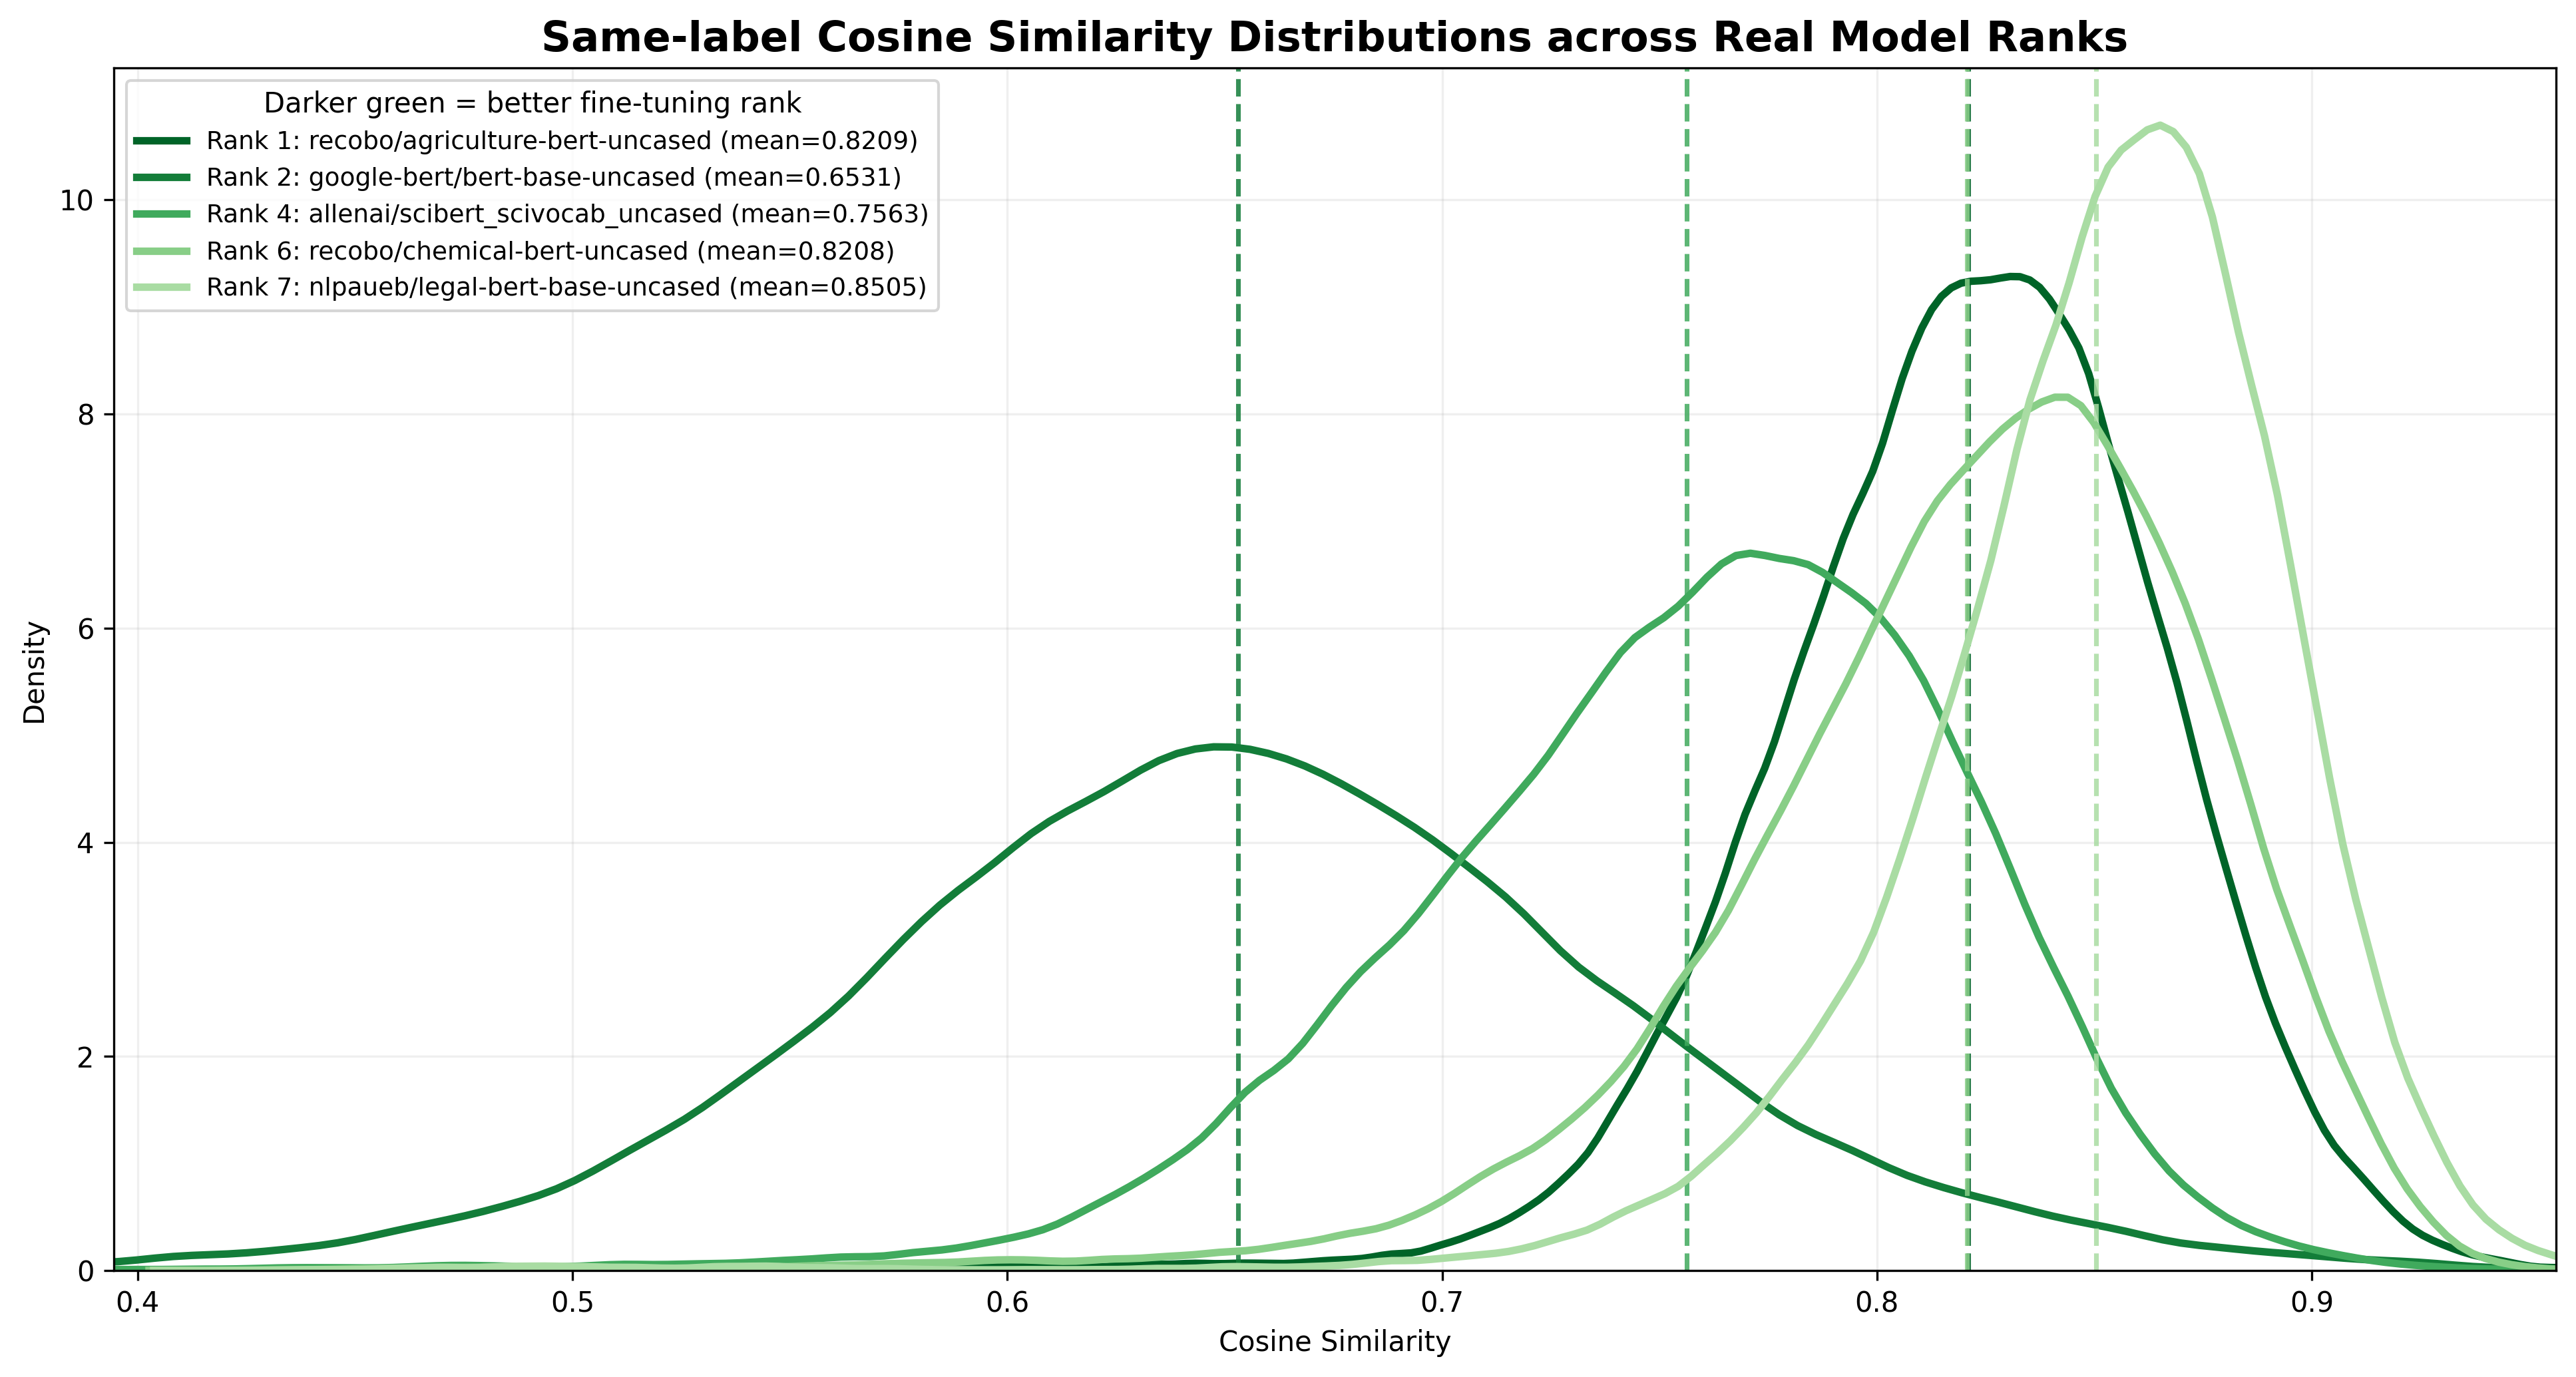

In [30]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "same_scores"
    ]

    mean_value = values[
        "same_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Same-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker green = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "financial_same_label_rank_spanning.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [31]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "diff_scores"
    ]

    mean_value = values[
        "diff_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Different-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker green = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "financial_different_label_rank_spanning.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()